# 03 · Machine-Learning Imitation

We treat the DP policy $y^\*(t,x)$ as a teacher and train a small MLP (student) by supervised imitation:
$$\text{input } (\tau, x)\ \longrightarrow\ \text{target } y^\*(t,x),\qquad \tau=t/N.$$
The student is a 2×64 tanh MLP with a sigmoid output (so $y\in[0,1]$), trained with Adam on MSE.

In [1]:
import os, sys
ROOT = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt


In [2]:
from src.config import Config
from src.dp_solver import solve
from src.ml_policy import build_dataset, train_policy, policy_action
from src import visualization as viz
# Lighter epoch budget for a quick notebook run.
cfg = Config(ml_epochs=150)
sol = solve(cfg)
X, Y = build_dataset(sol)
print(f'Dataset: X={X.shape} (columns [tau, x]), Y={Y.shape}')
print(f'tau range [{X[:,0].min():.3f},{X[:,0].max():.3f}], x range [{X[:,1].min():.3f},{X[:,1].max():.3f}]')

Dataset: X=(10452, 2) (columns [tau, x]), Y=(10452, 1)
tau range [0.000,0.981], x range [0.000,1.000]


In [3]:
model, hist = train_policy(sol, cfg, verbose=True)
n_params = sum(p.numel() for p in model.parameters())
print(f'\nParameters: {n_params};  final val MSE = {hist.final_val:.3e}')

  epoch    0: train MSE=2.032e-02  val MSE=1.220e-02


  epoch   15: train MSE=1.702e-03  val MSE=1.622e-03


  epoch   30: train MSE=7.488e-04  val MSE=7.272e-04


  epoch   45: train MSE=5.133e-04  val MSE=5.228e-04


  epoch   60: train MSE=4.100e-04  val MSE=4.013e-04


  epoch   75: train MSE=3.588e-04  val MSE=3.549e-04


  epoch   90: train MSE=3.217e-04  val MSE=3.441e-04


  epoch  105: train MSE=3.016e-04  val MSE=3.008e-04


  epoch  120: train MSE=2.851e-04  val MSE=2.846e-04


  epoch  135: train MSE=2.710e-04  val MSE=2.711e-04



Parameters: 4417;  final val MSE = 2.531e-04


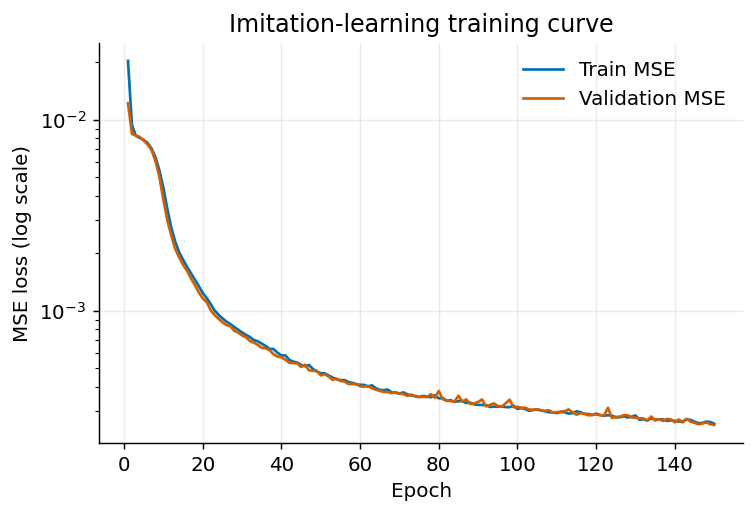

In [4]:
viz.plot_training_history(hist); plt.show()

## Learned vs optimal policy
The network captures the overall shape but **smooths the kinks** of the no-trade region: inside the band, where the optimum is exactly $y=x$, the smooth approximation lies slightly off the diagonal.

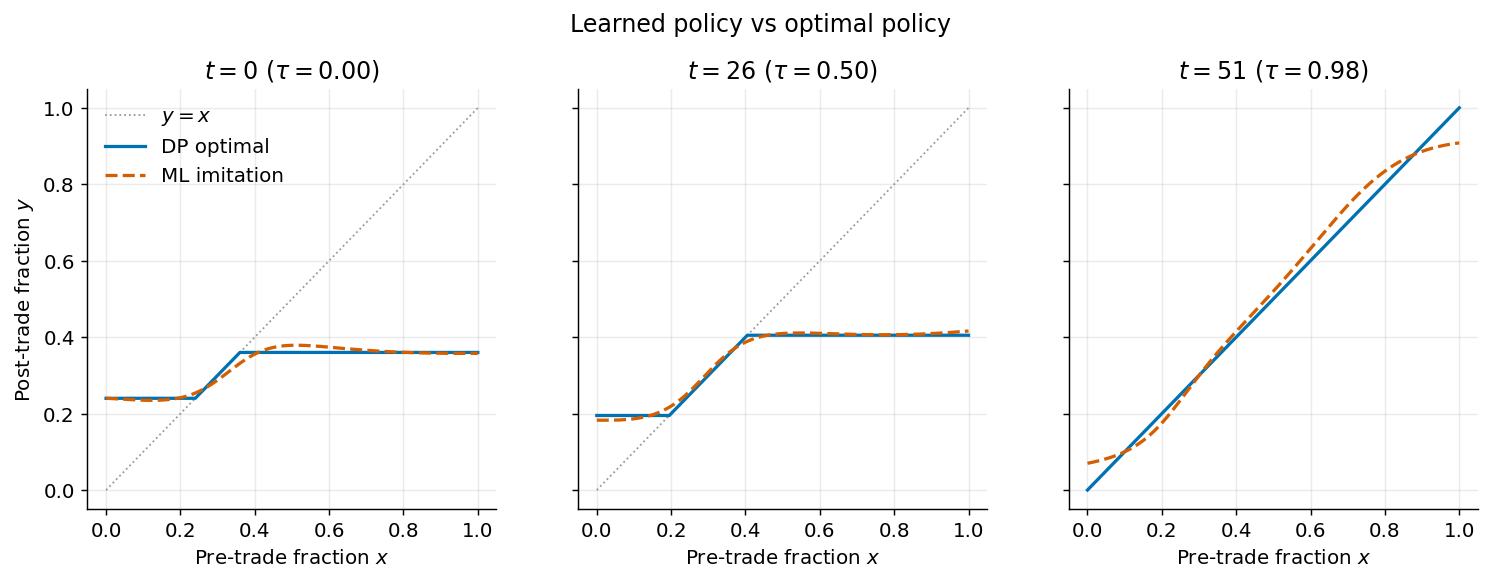

In [5]:
viz.plot_dp_vs_ml(sol, model, cfg); plt.show()

## Why smoothness is costly: the no-trade region is hard to imitate
A regressor cannot represent the exact identity $y=x$ on a positive-measure set without infinitely sharp kinks. The residual $|y_{ML}-x|$ inside the band is tiny in MSE terms yet **non-zero everywhere**, so the imitation policy keeps trading where the optimum would hold. We quantify the residual inside the $t=0$ band:

In [6]:
lo,hi = sol.no_trade_band(0)
xs = np.linspace(lo, hi, 50)
y_ml = policy_action(model, np.zeros_like(xs), xs)
resid = np.abs(y_ml - xs)
print(f'Inside the t=0 no-trade band [{lo:.3f},{hi:.3f}]:')
print(f'  mean |y_ML - x| = {resid.mean():.4f}  (max {resid.max():.4f})')
print('Each non-zero residual is a trade the optimal policy would NOT make.')
print('This is the mechanism behind the ML turnover seen in 04_evaluation.')

Inside the t=0 no-trade band [0.235,0.365]:
  mean |y_ML - x| = 0.0143  (max 0.0299)
Each non-zero residual is a trade the optimal policy would NOT make.
This is the mechanism behind the ML turnover seen in 04_evaluation.


**Takeaway.** Low supervised error does **not** imply good control: imitation in *action space* ignores that small errors inside the no-trade region are economically amplified into turnover and cost. We measure the consequences in **04_evaluation**.